# 25 · Annual field predictions and food–water questions

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** compare annual predictions on common support; make a temporal visualization; design a defensible climate-impact study.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=25_ftw_change_food_water.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Difference is a calculation; change is an interpretation

Subtract 2024 probabilities from 2025 probabilities at the same pixels. This produces **a difference between
model outputs**, not a verified map of field creation, abandonment, drought or flood damage. Annual input
composites, crop cycles, clouds, model errors and real land changes can all contribute. Two annual layers
cannot establish a climate trend. Polygon IDs are not stable field identities across years.

Use a fixed paired-valid mask. If one year were missing, replacing it with zero would invent a difference.

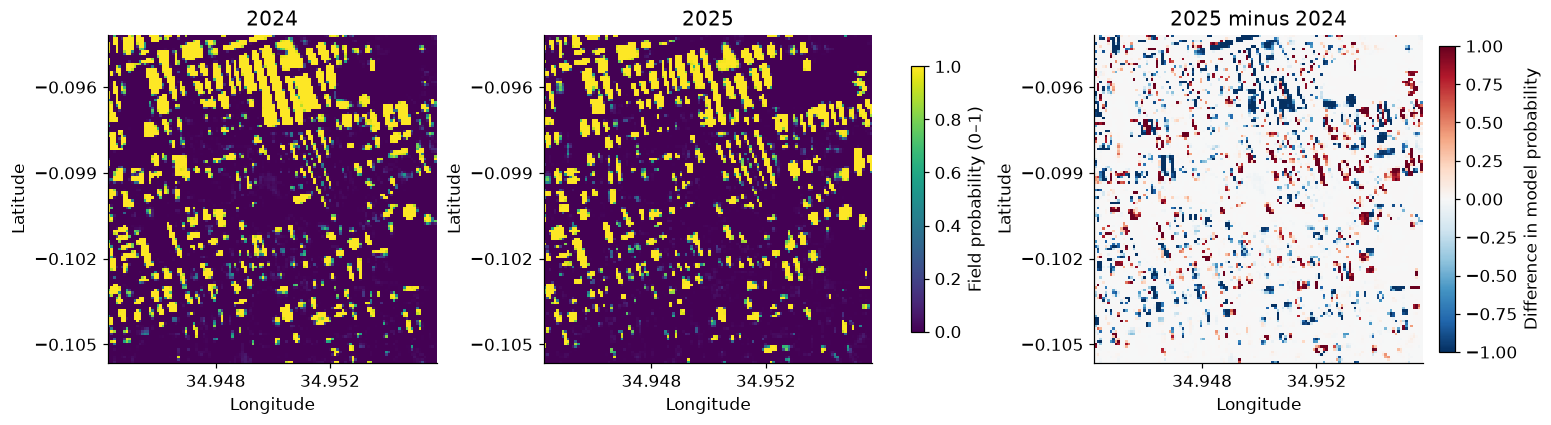

Paired valid pixels: 16384 of 16384
Mean paired difference: -0.02313
|difference| > 0.1 : 3044 pixels
|difference| > 0.25 : 2573 pixels
|difference| > 0.5 : 2083 pixels


In [2]:
from ftw import load_ftw, raster_map, paired_difference
d=load_ftw('kenya')
delta,paired=paired_difference(d['probability'])
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for t in range(2):
    annual=raster_map(axes[t],d,d['probability'][t,1],str(d['years'][t]))
fig.colorbar(annual,ax=axes[:2],label='Field probability (0–1)',shrink=.65)
image=raster_map(axes[2],d,delta,'2025 minus 2024',cmap='RdBu_r',vmin=-1,vmax=1)
fig.colorbar(image,ax=axes[2],label='Difference in model probability',shrink=.75)
plt.show()
print('Paired valid pixels:',paired.sum(),'of',paired.size)
print('Mean paired difference:',round(float(np.nanmean(delta)),5))
for cutoff in [.1,.25,.5]:
    print('|difference| >',cutoff,':',int(np.count_nonzero(np.abs(delta)>cutoff)),'pixels')

## 2. Animate the two snapshots without inventing intermediate years

The player alternates the two annual arrays with a fixed 0–1 color scale. There is no interpolation.
It is a teaching animation of predictions, not satellite video. Stop on each frame and read the year.
The static panels above carry the same evidence if animation is unavailable.

In [3]:
from matplotlib.animation import FuncAnimation
fig,ax=plt.subplots(figsize=(7,5))
image=raster_map(ax,d,d['probability'][0,1],'2024 / field probability')
fig.colorbar(image,ax=ax,label='Model class probability (0–1)')
def frame(i):
    image.set_array(d['probability'][i,1].ravel())
    ax.set_title(f"{d['years'][i]} / field probability / annual model output")
    return (image,)
animation=FuncAnimation(fig,frame,frames=2,interval=1200,repeat=True)
display(HTML(animation.to_jshtml(default_mode='once')))
plt.close(fig)

## 3. Compare representations before making a claim

Even if field probability changes little, a threshold can split or merge connected areas and alter polygon counts.
Try several pixel thresholds and compare annual selected-pixel counts. These are model sensitivities, not a
validation against independent field observations.

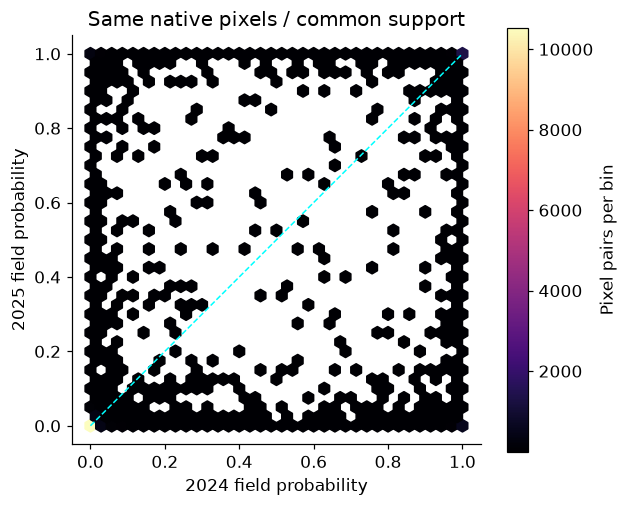

threshold 0.3 2024 / 2025: 3357 2946
threshold 0.5 2024 / 2025: 3149 2745
threshold 0.7 2024 / 2025: 2963 2606


In [4]:
fig,ax=plt.subplots(figsize=(6,5))
a=d['probability'][0,1][paired];b=d['probability'][1,1][paired]
image=ax.hexbin(a,b,gridsize=35,extent=(0,1,0,1),mincnt=1,cmap='magma')
ax.plot([0,1],[0,1],'--',color='cyan',lw=1)
ax.set(xlabel='2024 field probability',ylabel='2025 field probability',title='Same native pixels / common support',aspect='equal')
fig.colorbar(image,ax=ax,label='Pixel pairs per bin');plt.show()
for threshold in [.3,.5,.7]:
    print('threshold',threshold,'2024 / 2025:',int((a>threshold).sum()),int((b>threshold).sum()))

## 4. Connect fields to climate and food–water questions

FTW can provide candidate spatial units for a study. It does not supply the hazard, exposure, yields, irrigation,
markets, access to food, or adaptation capacity needed to assess impacts. For example:

| Question | Evidence to add | Matching / validation task |
|---|---|---|
| Were predicted fields exposed to flooding? | Event-dated water maps and local flood observations | Intersect contemporaneous fields and water; test cloud/missing-data masks |
| Did water stress affect crops? | Rainfall, soil moisture, crop calendar, irrigation and measured yields | Match seasons and spatial support; check field data and alternative causes |
| Could rising seas affect delta agriculture? | Local elevation/datum, salinity, defenses, drainage and sea-level projections | Use hydraulic/salinity evidence; a sea-level offset is not an inundation map |
| Is a household food insecure? | Consented socioeconomic and food-access evidence | A field outline cannot identify household circumstances |

The course's Digital Earth Africa water example is at Lake Ngami, **not these FTW windows**. Do not spatially
join it here. Retrieve compatible, dated coverage for the actual study area and preserve its license and uncertainty.
The Lagos and Abidjan GeoTessera extracts likewise do not overlap these windows. Embedding similarity is not
a substitute for a validated crop or hazard classifier. Country-level comparisons require a sampling design.

## 5. Instructor exercise: an evidence plan

Write one bounded question, the unit of analysis, dates, a spatial selection rule, a missing-data policy,
a confidence-sensitivity analysis, independent validation, and an attribution statement.
Peer review using five criteria (4 points each): scope, reproducibility, provenance, visual reasoning and interpretation.

In [5]:
plan={
 'question':'Where do these two annual FTW model outputs differ?',
 'region':d['region']['title'], 'years':d['years'],
 'method':'2025 minus 2024 field probability, paired finite native pixels',
 'claim_limit':'Differences are not independently verified land change or climate attribution',
 'next_evidence':['Dated Sentinel-2 imagery','Independent field boundaries and local interpretation','Seasonally matched hazard observations'],
 'citation':d['provenance']['paper'], 'license':d['provenance']['license']
}
print(json.dumps(plan,indent=2))

{
  "question": "Where do these two annual FTW model outputs differ?",
  "region": "Western Kenya teaching window",
  "years": [
    2024,
    2025
  ],
  "method": "2025 minus 2024 field probability, paired finite native pixels",
  "claim_limit": "Differences are not independently verified land change or climate attribution",
  "next_evidence": [
    "Dated Sentinel-2 imagery",
    "Independent field boundaries and local interpretation",
    "Seasonally matched hazard observations"
  ],
  "citation": "https://doi.org/10.48550/arXiv.2605.11055",
  "license": "CC-BY-4.0"
}


## Try it yourself

Repeat for Senegal. Draft a flood-exposure study with compatible observations; state why a change in polygon count alone would not validate its conclusion.

## Check your reasoning

A defensible study aligns dates, support and meaning across data sources, tests selection effects and validates with independent evidence. Model differences alone cannot establish a climate burden.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Global Fields of the World on Source Cooperative](https://source.coop/ftw/global-data), Taylor Geospatial and collaborators, CC-BY-4.0.
- [Robinson et al. (2026), The first global agricultural field boundary map at 10 m resolution](https://doi.org/10.48550/arXiv.2605.11055).
- [Pinned official FTW catalog and product documentation](https://github.com/fieldsoftheworld/ftw-data-catalog/tree/fd844c4c646af0f8e653fba774f79cc17b2af124/catalog). PRUE model predictions use Copernicus Sentinel-2 composites.
- [Exact extracts, source ETags, spatial selection and SHA256 checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ftw-provenance.json). Local modifications: spatial subsets, GeoJSON conversion and scalar Zarr repackaging; original class values and full selected polygon geometries retained.
- [Digital Earth Africa Water Observations from Space specifications](https://docs.digitalearthafrica.org/en/latest/data_specs/Landsat_WOfS_specs.html).
- [IPCC AR6 WGII Chapter 9: Africa](https://www.ipcc.ch/report/ar6/wg2/chapter/chapter-9/), context for climate impacts, vulnerability and adaptation.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 25_ftw_change_food_water')

LESSON COMPLETE: 25_ftw_change_food_water
